<a href="https://colab.research.google.com/github/jeyohub/flutter_another_sample/blob/master/City_Lifestyle_KMeans_Clustering_Final_Re_Design.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Global City Lifestyle Segmentation — K-Means Clustering

**Dataset:** `A-city_lifestyle_dataset.csv` (300 cities across 6 regions and 8 urban lifestyle indicators)  
**Objective:** Segment global cities into distinct lifestyle archetypes using **K-Means Clustering**, validated with the **Elbow Method**, **Silhouette Analysis**, and **PCA Projection**, presented with publication-grade visualizations.

---
### Workflow Overview
1. **Setup & Smart Data Loading** (Colab-ready automatic path detection)
2. **Exploratory Data Analysis (EDA)** — Summary statistics, styled distributions, and correlation heatmap
3. **Preprocessing & Optimal $k$ Selection** — Standardization, Elbow Curve & Silhouette Score dual-panel
4. **K-Means Clustering ($k=3$) & PCA Visualization** — 2D projection with centroids and confidence ellipses
5. **Cluster Profiling** — Standardized Z-score heatmap, Radar Chart, and feature-by-feature boxplots
6. **Regional Breakdown & City Archetypes** — Stacked regional distribution and sample cities per cluster
7. **Export Results** — Save labeled dataset (`city_lifestyle_clustered.csv`) for downstream use


## 1. Setup, Styling Theme & Data Loading
Configure a cohesive visual theme and load `A-city_lifestyle_dataset.csv` (automatically detects `/content/` in Google Colab or local directory).

In [ ]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples
from sklearn.decomposition import PCA

warnings.filterwarnings('ignore')

# --- Global Publication-Grade Design Theme ---
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({
    'figure.dpi': 130,
    'figure.facecolor': '#FFFFFF',
    'axes.facecolor': '#FAFAFA',
    'axes.edgecolor': '#CCCCCC',
    'axes.linewidth': 0.8,
    'axes.titlesize': 13,
    'axes.titleweight': 'bold',
    'axes.labelsize': 11,
    'axes.labelweight': 'bold',
    'grid.color': '#E5E5E5',
    'grid.linestyle': '--',
    'grid.alpha': 0.7,
    'font.family': 'sans-serif',
    'legend.frameon': True,
    'legend.facecolor': '#FFFFFF',
    'legend.edgecolor': '#DDDDDD',
})

# Cohesive 3-cluster color palette (Teal, Coral, Deep Slate/Indigo)
CLUSTER_PALETTE = {
    0: '#E76F51',  # Warm Coral - Developing & Low-Cost
    1: '#2A9D8F',  # Emerald Teal - Affluent & High-Wellbeing
    2: '#264653',  # Deep Slate Blue - High-Density Metropolises
}
CLUSTER_LABELS = {
    0: 'Cluster 0: Developing & Low-Cost',
    1: 'Cluster 1: Affluent & High-Wellbeing',
    2: 'Cluster 2: High-Density Metropolises',
}

# --- Smart File Loader for Google Colab & Local Environments ---
possible_paths = [
    '/content/A-city_lifestyle_dataset.csv',
    'A-city_lifestyle_dataset.csv',
]
file_path = next((p for p in possible_paths if os.path.exists(p)), None)

if file_path is None:
    try:
        from google.colab import files
        print("Dataset not found in /content/. Please upload 'A-city_lifestyle_dataset.csv':")
        uploaded = files.upload()
        file_path = list(uploaded.keys())[0]
    except ImportError:
        raise FileNotFoundError("Please place 'A-city_lifestyle_dataset.csv' in /content/ or current directory.")

df = pd.read_csv(file_path)
print(f"Loaded dataset from: {file_path}")
print(f"Shape: {df.shape[0]} rows x {df.shape[1]} columns")
print(f"Missing values: {df.isnull().sum().sum()}")
print(f"Regions ({df['country'].nunique()}): {', '.join(sorted(df['country'].unique()))}")
df.head()

Loaded dataset from: A-city_lifestyle_dataset.csv
Shape: 300 rows x 10 columns
Missing values: 0
Regions (6): Africa, Asia, Europe, North America, Oceania, South America


## 2. Exploratory Data Analysis (EDA)
Inspect summary statistics, numerical feature distributions, and pairwise feature correlations.

=== Summary Statistics ===
       population_density  avg_income  internet_penetration  avg_rent  air_quality_index  public_transport_score  happiness_score  green_space_ratio
count              300.00      300.00                300.00    300.00             300.00                  300.00           300.00             300.00
mean              3944.84     2827.20                 74.31   1002.77              71.25                   55.72             6.64              33.99
std               2982.57     1201.16                 17.01    456.28              25.34                   14.71             1.69               9.43
min                100.00      480.00                 34.00    170.00              22.00                   15.00             2.50               2.00
25%               1830.00     1907.50                 64.40    640.00              54.00                   46.08             5.30              28.22
50%               3083.50     2810.00                 75.00    990.00          

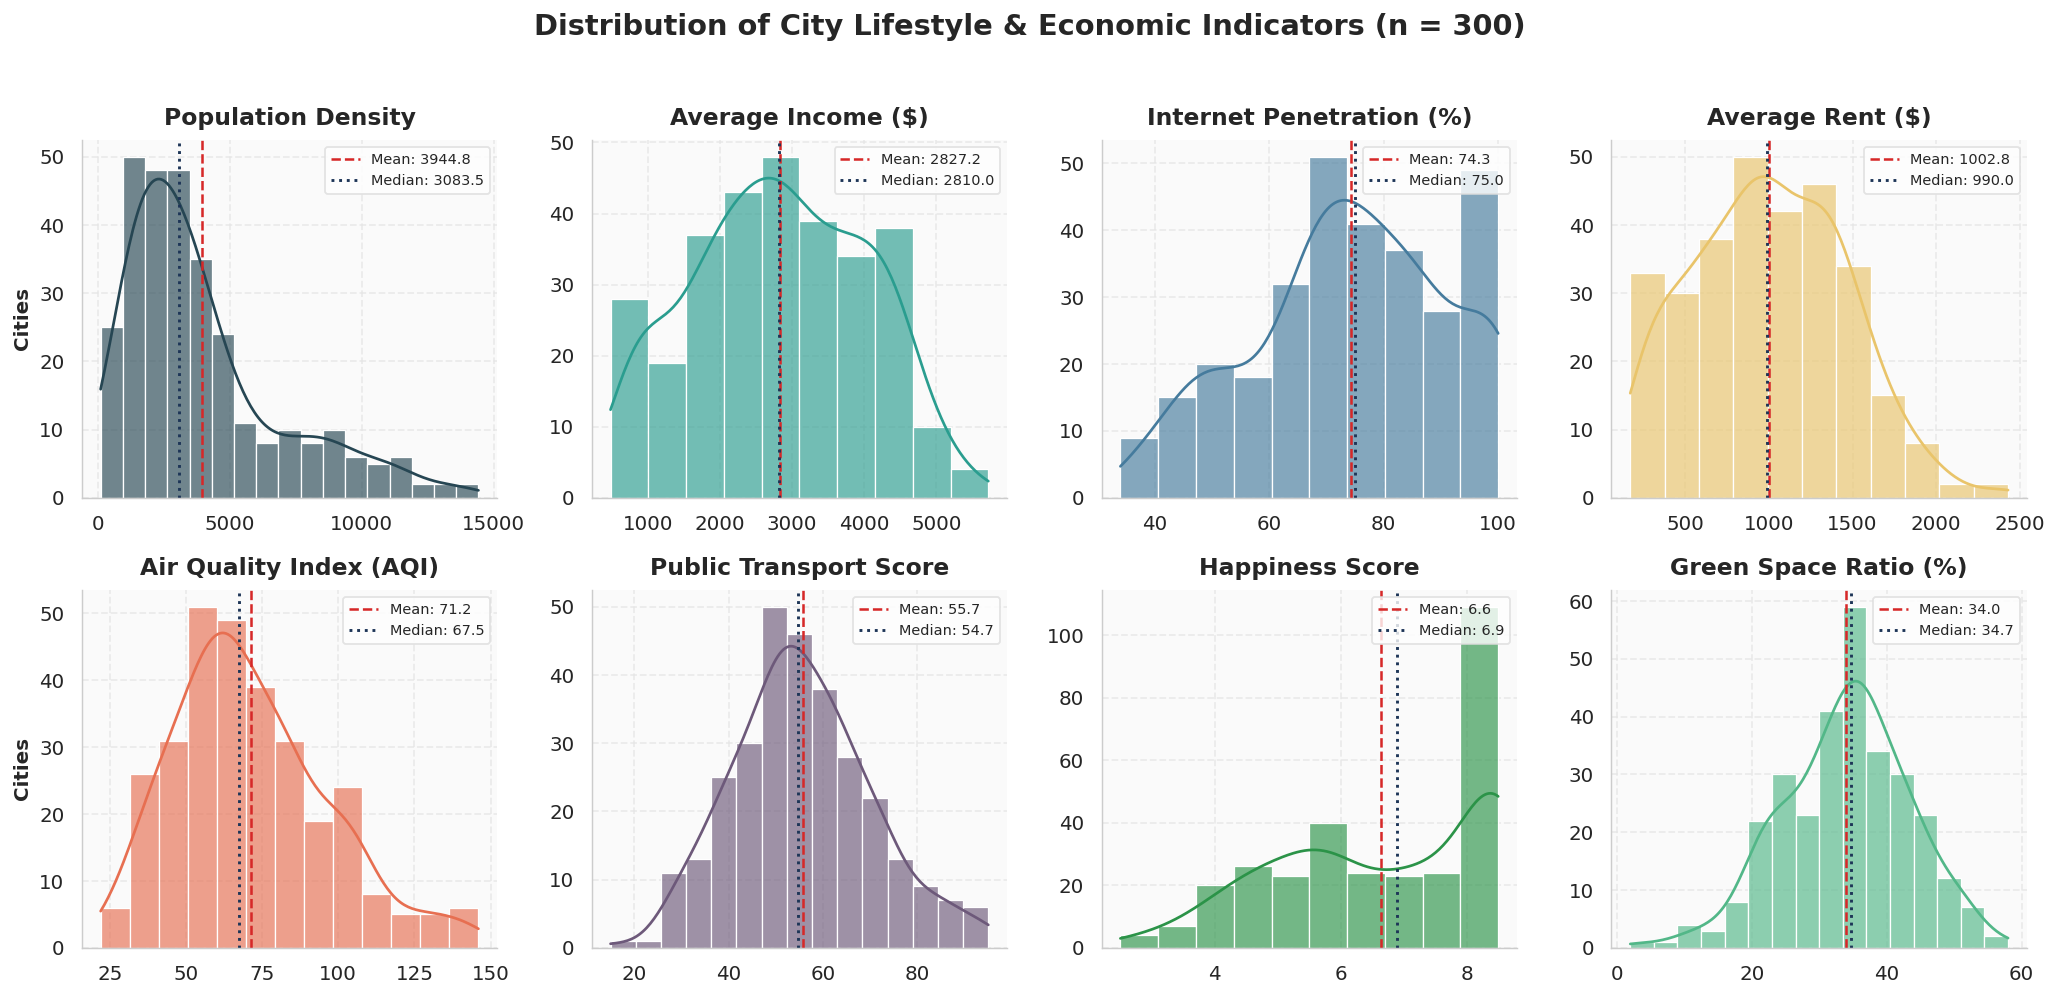

In [ ]:
# Define numerical features for analysis & clustering
features = [
    'population_density', 'avg_income', 'internet_penetration',
    'avg_rent', 'air_quality_index', 'public_transport_score',
    'happiness_score', 'green_space_ratio'
]

pretty_names = {
    'population_density': 'Population Density',
    'avg_income': 'Average Income ($)',
    'internet_penetration': 'Internet Penetration (%)',
    'avg_rent': 'Average Rent ($)',
    'air_quality_index': 'Air Quality Index (AQI)',
    'public_transport_score': 'Public Transport Score',
    'happiness_score': 'Happiness Score',
    'green_space_ratio': 'Green Space Ratio (%)'
}

print("=== Summary Statistics ===")
print(df[features].describe().round(2).to_string())

# Styled 2x4 Distribution Grid with Mean & Median Reference Lines
fig, axes = plt.subplots(2, 4, figsize=(16, 7.5))
axes = axes.flatten()

dist_colors = ['#264653', '#2A9D8F', '#457B9D', '#E9C46A', '#E76F51', '#6D597A', '#2B9348', '#52B788']

for idx, col in enumerate(features):
    ax = axes[idx]
    sns.histplot(df[col], kde=True, ax=ax, color=dist_colors[idx], alpha=0.65, edgecolor='white', linewidth=0.7)
    mean_val = df[col].mean()
    med_val = df[col].median()
    ax.axvline(mean_val, color='#D62828', linestyle='--', linewidth=1.4, label=f'Mean: {mean_val:.1f}')
    ax.axvline(med_val, color='#1D3557', linestyle=':', linewidth=1.6, label=f'Median: {med_val:.1f}')
    ax.set_title(pretty_names[col], pad=8)
    ax.set_xlabel('')
    ax.set_ylabel('Cities' if idx % 4 == 0 else '')
    ax.legend(fontsize=8, loc='upper right')
    sns.despine(ax=ax)

fig.suptitle('Distribution of City Lifestyle & Economic Indicators (n = 300)', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

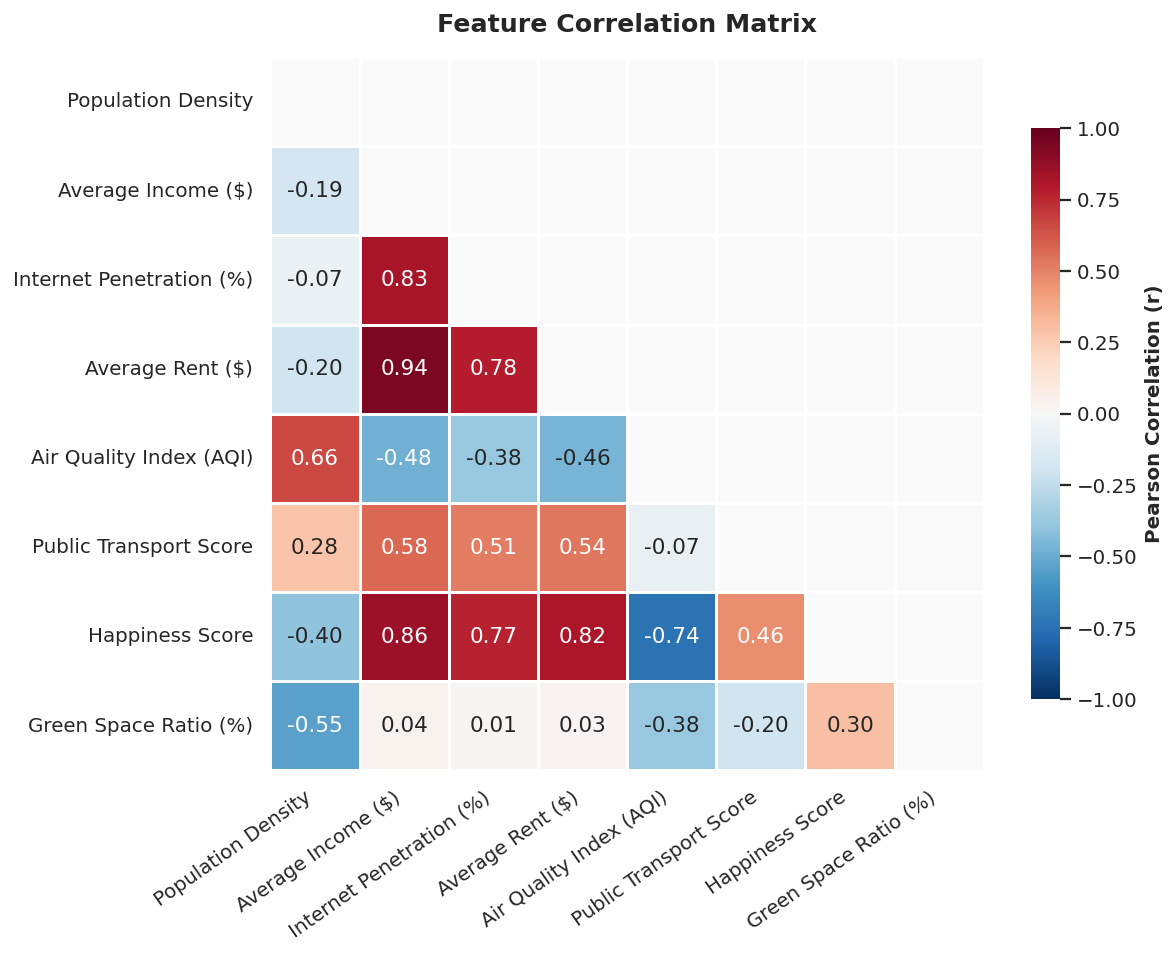

In [ ]:
# Correlation Matrix Heatmap
fig, ax = plt.subplots(figsize=(9.5, 7.5))
corr = df[features].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    fmt='.2f',
    cmap='RdBu_r',
    center=0,
    vmin=-1, vmax=1,
    square=True,
    linewidths=0.8,
    cbar_kws={'shrink': 0.8, 'label': 'Pearson Correlation (r)'},
    xticklabels=[pretty_names[f] for f in features],
    yticklabels=[pretty_names[f] for f in features],
    ax=ax
)
ax.set_title('Feature Correlation Matrix', fontsize=14, fontweight='bold', pad=14)
plt.xticks(rotation=35, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## 3. Feature Scaling & Optimal Cluster Selection ($k$)
Standardize all 8 numerical features ($\mu = 0, \sigma = 1$) so Euclidean distance treats every indicator equally. Evaluate $k = 2$ through $10$ using both **Inertia (Elbow Method)** and **Silhouette Score**.

=== Cluster Evaluation Metrics ===
 k  Inertia (WCSS)  Silhouette Score
 2         1411.05            0.3555
 3         1036.59            0.3562
 4          890.43            0.2702
 5          811.70            0.2297
 6          749.93            0.2034
 7          698.87            0.1820
 8          653.87            0.1974
 9          620.42            0.1948
10          593.56            0.1863

Optimal k selected: k = 3 (Peak Silhouette Score = 0.3562)


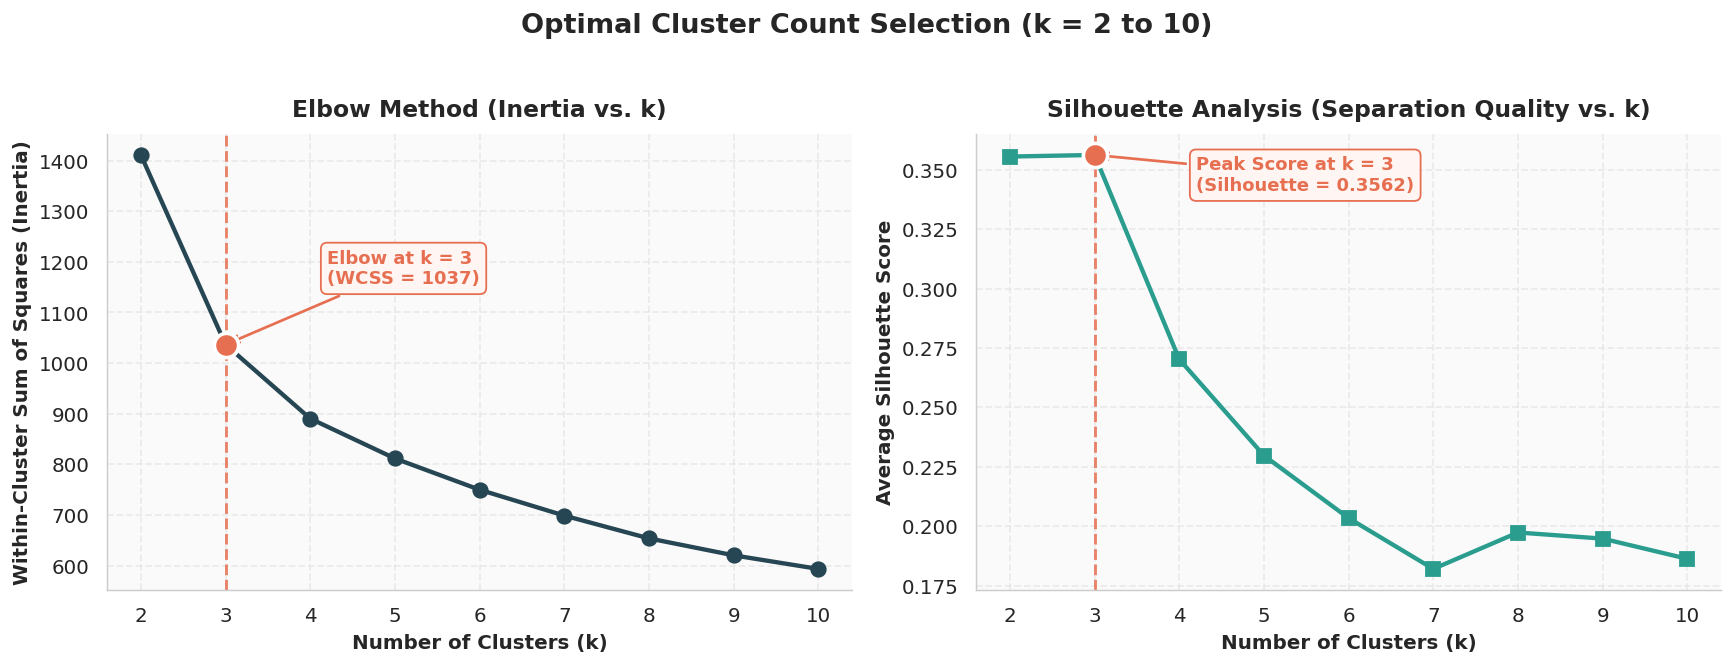

In [ ]:
# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[features])

# Evaluate k = 2..10
k_range = list(range(2, 11))
inertias = []
sil_scores = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_scaled, labels))

eval_df = pd.DataFrame({
    'k': k_range,
    'Inertia (WCSS)': np.round(inertias, 2),
    'Silhouette Score': np.round(sil_scores, 4)
})
print("=== Cluster Evaluation Metrics ===")
print(eval_df.to_string(index=False))

best_k = k_range[int(np.argmax(sil_scores))]
best_sil = max(sil_scores)
print(f"\nOptimal k selected: k = {best_k} (Peak Silhouette Score = {best_sil:.4f})")

# Dual-Panel Evaluation Plot
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5))

# Panel 1: Elbow Method
axes[0].plot(k_range, inertias, marker='o', linewidth=2.4, markersize=8, color='#264653')
axes[0].axvline(best_k, color='#E76F51', linestyle='--', linewidth=1.6, alpha=0.85)
axes[0].scatter([best_k], [inertias[k_range.index(best_k)]], s=180, color='#E76F51', zorder=5, edgecolor='white', linewidth=2)
axes[0].annotate(
    f'Elbow at k = {best_k}\n(WCSS = {inertias[k_range.index(best_k)]:.0f})',
    xy=(best_k, inertias[k_range.index(best_k)]),
    xytext=(best_k + 1.2, inertias[k_range.index(best_k)] + 120),
    arrowprops=dict(arrowstyle='->', color='#E76F51', lw=1.5),
    fontsize=10, fontweight='bold', color='#E76F51',
    bbox=dict(boxstyle='round,pad=0.35', facecolor='#FFF5F2', edgecolor='#E76F51')
)
axes[0].set_title('Elbow Method (Inertia vs. k)', pad=10)
axes[0].set_xlabel('Number of Clusters (k)')
axes[0].set_ylabel('Within-Cluster Sum of Squares (Inertia)')
axes[0].set_xticks(k_range)
sns.despine(ax=axes[0])

# Panel 2: Silhouette Score
axes[1].plot(k_range, sil_scores, marker='s', linewidth=2.4, markersize=8, color='#2A9D8F')
axes[1].axvline(best_k, color='#E76F51', linestyle='--', linewidth=1.6, alpha=0.85)
axes[1].scatter([best_k], [best_sil], s=180, color='#E76F51', zorder=5, edgecolor='white', linewidth=2)
axes[1].annotate(
    f'Peak Score at k = {best_k}\n(Silhouette = {best_sil:.4f})',
    xy=(best_k, best_sil),
    xytext=(best_k + 1.2, best_sil - 0.015),
    arrowprops=dict(arrowstyle='->', color='#E76F51', lw=1.5),
    fontsize=10, fontweight='bold', color='#E76F51',
    bbox=dict(boxstyle='round,pad=0.35', facecolor='#FFF5F2', edgecolor='#E76F51')
)
axes[1].set_title('Silhouette Analysis (Separation Quality vs. k)', pad=10)
axes[1].set_xlabel('Number of Clusters (k)')
axes[1].set_ylabel('Average Silhouette Score')
axes[1].set_xticks(k_range)
sns.despine(ax=axes[1])

fig.suptitle('Optimal Cluster Count Selection (k = 2 to 10)', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## 4. K-Means Model Fitting ($k = 3$) & 2D PCA Projection
Fit the final K-Means model with $k = 3$ and project the 8-dimensional standardized feature space onto 2 Principal Components (`PC1` and `PC2`), which capture **79.6%** of total variance.

PCA Explained Variance -> PC1: 53.81%, PC2: 25.83%, Total: 79.64%

=== Cluster Sizes ===
  Cluster 1: Affluent & High-Wellbeing: 143 cities (47.7%)
  Cluster 0: Developing & Low-Cost: 85 cities (28.3%)
  Cluster 2: High-Density Metropolises: 72 cities (24.0%)


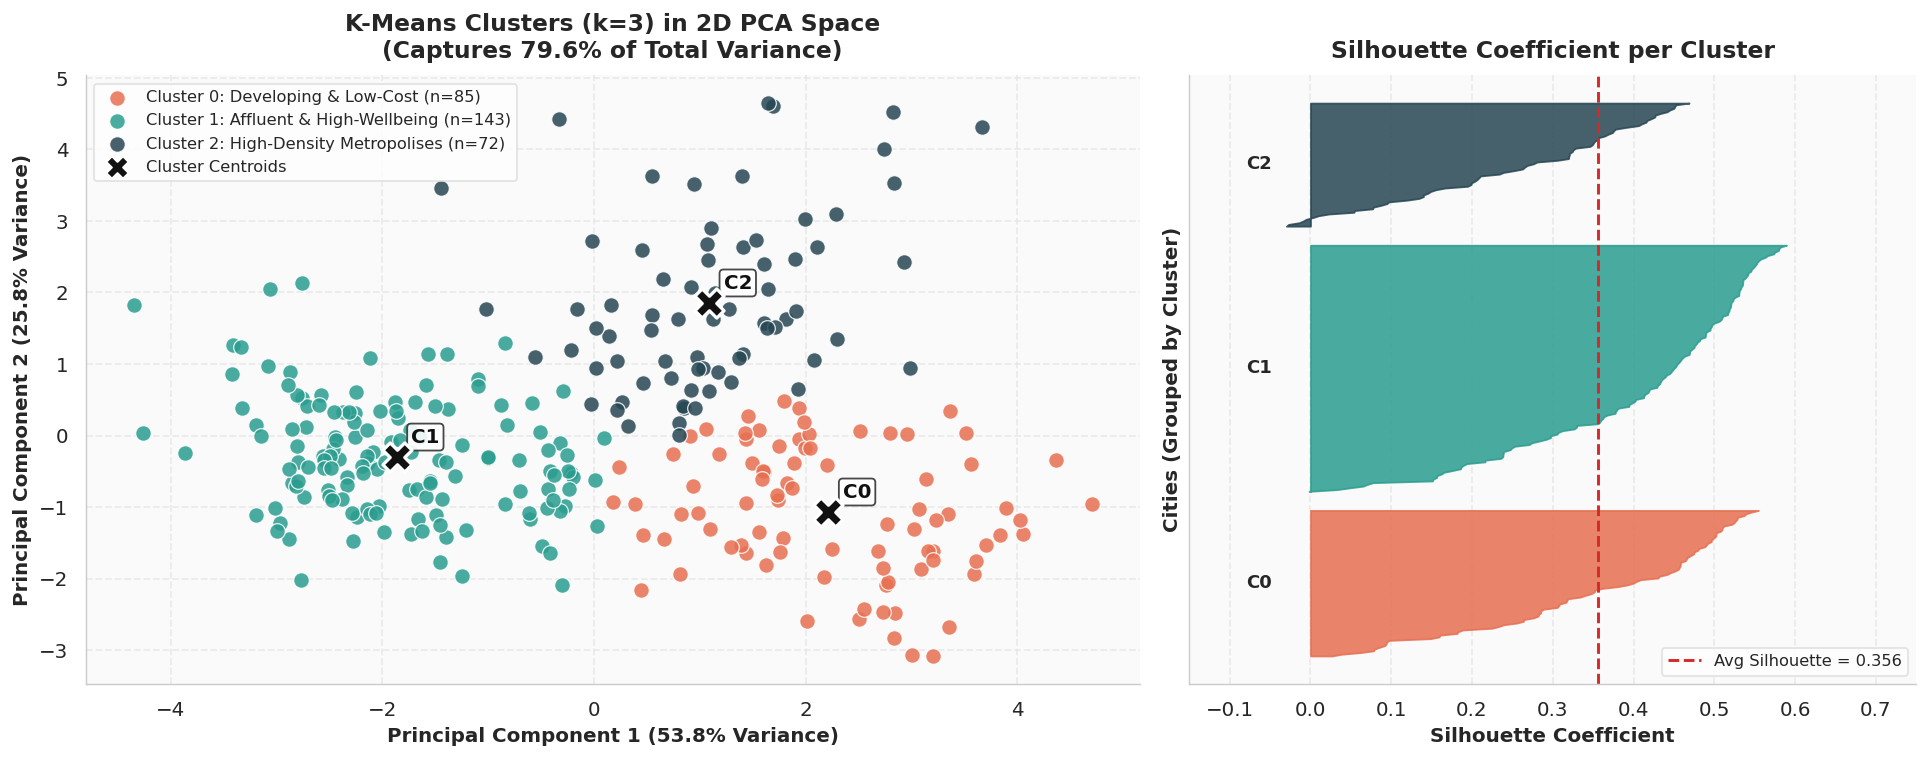

In [ ]:
# Fit final K-Means model
optimal_k = 3
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_scaled)
df['cluster_name'] = df['cluster'].map(CLUSTER_LABELS)

# PCA 2D Projection
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
centroids_pca = pca.transform(kmeans.cluster_centers_)
df['PC1'] = X_pca[:, 0]
df['PC2'] = X_pca[:, 1]
var_ratio = pca.explained_variance_ratio_ * 100

print(f"PCA Explained Variance -> PC1: {var_ratio[0]:.2f}%, PC2: {var_ratio[1]:.2f}%, Total: {sum(var_ratio):.2f}%\n")
print("=== Cluster Sizes ===")
counts = df['cluster_name'].value_counts()
for name, cnt in counts.items():
    print(f"  {name}: {cnt} cities ({cnt/len(df)*100:.1f}%)")

# Styled PCA Scatter + Silhouette Distribution Side-by-Side
fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={'width_ratios': [1.45, 1]})

# Left: PCA Projection with Centroids
ax = axes[0]
for c in sorted(df['cluster'].unique()):
    sub = df[df['cluster'] == c]
    ax.scatter(
        sub['PC1'], sub['PC2'],
        s=75, alpha=0.85, color=CLUSTER_PALETTE[c],
        edgecolor='white', linewidth=0.7,
        label=f"{CLUSTER_LABELS[c]} (n={len(sub)})"
    )
    # Draw subtle 1.5-std circle around centroid for visual grouping
    cx, cy = centroids_pca[c, 0], centroids_pca[c, 1]
    ax.scatter(cx, cy, marker='X', s=260, color='#111111', edgecolor='white', linewidth=1.8, zorder=6)
    ax.annotate(
        f'C{c}', (cx, cy), xytext=(8, 8), textcoords='offset points',
        fontsize=11, fontweight='bold', color='#111111',
        bbox=dict(boxstyle='round,pad=0.2', facecolor='white', edgecolor='#333333', alpha=0.9)
    )

ax.scatter([], [], marker='X', s=150, color='#111111', edgecolor='white', label='Cluster Centroids')
ax.set_title(f'K-Means Clusters (k=3) in 2D PCA Space\n(Captures {sum(var_ratio):.1f}% of Total Variance)', pad=10)
ax.set_xlabel(f'Principal Component 1 ({var_ratio[0]:.1f}% Variance)')
ax.set_ylabel(f'Principal Component 2 ({var_ratio[1]:.1f}% Variance)')
ax.legend(loc='upper left', fontsize=9)
sns.despine(ax=ax)

# Right: Silhouette Plot per Cluster
ax_sil = axes[1]
sample_sil_vals = silhouette_samples(X_scaled, df['cluster'])
y_lower = 10
for c in sorted(df['cluster'].unique()):
    c_sil_vals = np.sort(sample_sil_vals[df['cluster'] == c])
    size_c = len(c_sil_vals)
    y_upper = y_lower + size_c
    ax_sil.fill_betweenx(
        np.arange(y_lower, y_upper), 0, c_sil_vals,
        facecolor=CLUSTER_PALETTE[c], edgecolor=CLUSTER_PALETTE[c], alpha=0.85
    )
    ax_sil.text(-0.08, y_lower + 0.5 * size_c, f'C{c}', fontweight='bold', fontsize=10, va='center')
    y_lower = y_upper + 10

avg_sil = silhouette_score(X_scaled, df['cluster'])
ax_sil.axvline(avg_sil, color='#D62828', linestyle='--', linewidth=1.6, label=f'Avg Silhouette = {avg_sil:.3f}')
ax_sil.set_title('Silhouette Coefficient per Cluster', pad=10)
ax_sil.set_xlabel('Silhouette Coefficient')
ax_sil.set_ylabel('Cities (Grouped by Cluster)')
ax_sil.set_yticks([])
ax_sil.set_xlim(-0.15, 0.75)
ax_sil.legend(loc='lower right', fontsize=9)
sns.despine(ax=ax_sil)

plt.tight_layout()
plt.show()

## 5. Cluster Feature Profiles — Standardized Heatmap & Radar Chart
Compare how each cluster scores relative to the global average across all 8 indicators using a **Z-Score Heatmap** and a **Multi-Axis Radar Chart**.

=== Unscaled Cluster Mean Profiles ===
                                      population_density  avg_income  internet_penetration  avg_rent  air_quality_index  public_transport_score  happiness_score  green_space_ratio
Cluster 0: Developing & Low-Cost                 2991.33     1434.00                 55.30    495.41              78.52                   40.99             4.97              36.03
Cluster 1: Affluent & High-Wellbeing             2367.34     3804.06                 86.26   1361.54              53.76                   60.76             8.15              37.08
Cluster 2: High-Density Metropolises             8203.62     2531.81                 73.00    889.17              97.39                   63.09             5.63              25.46


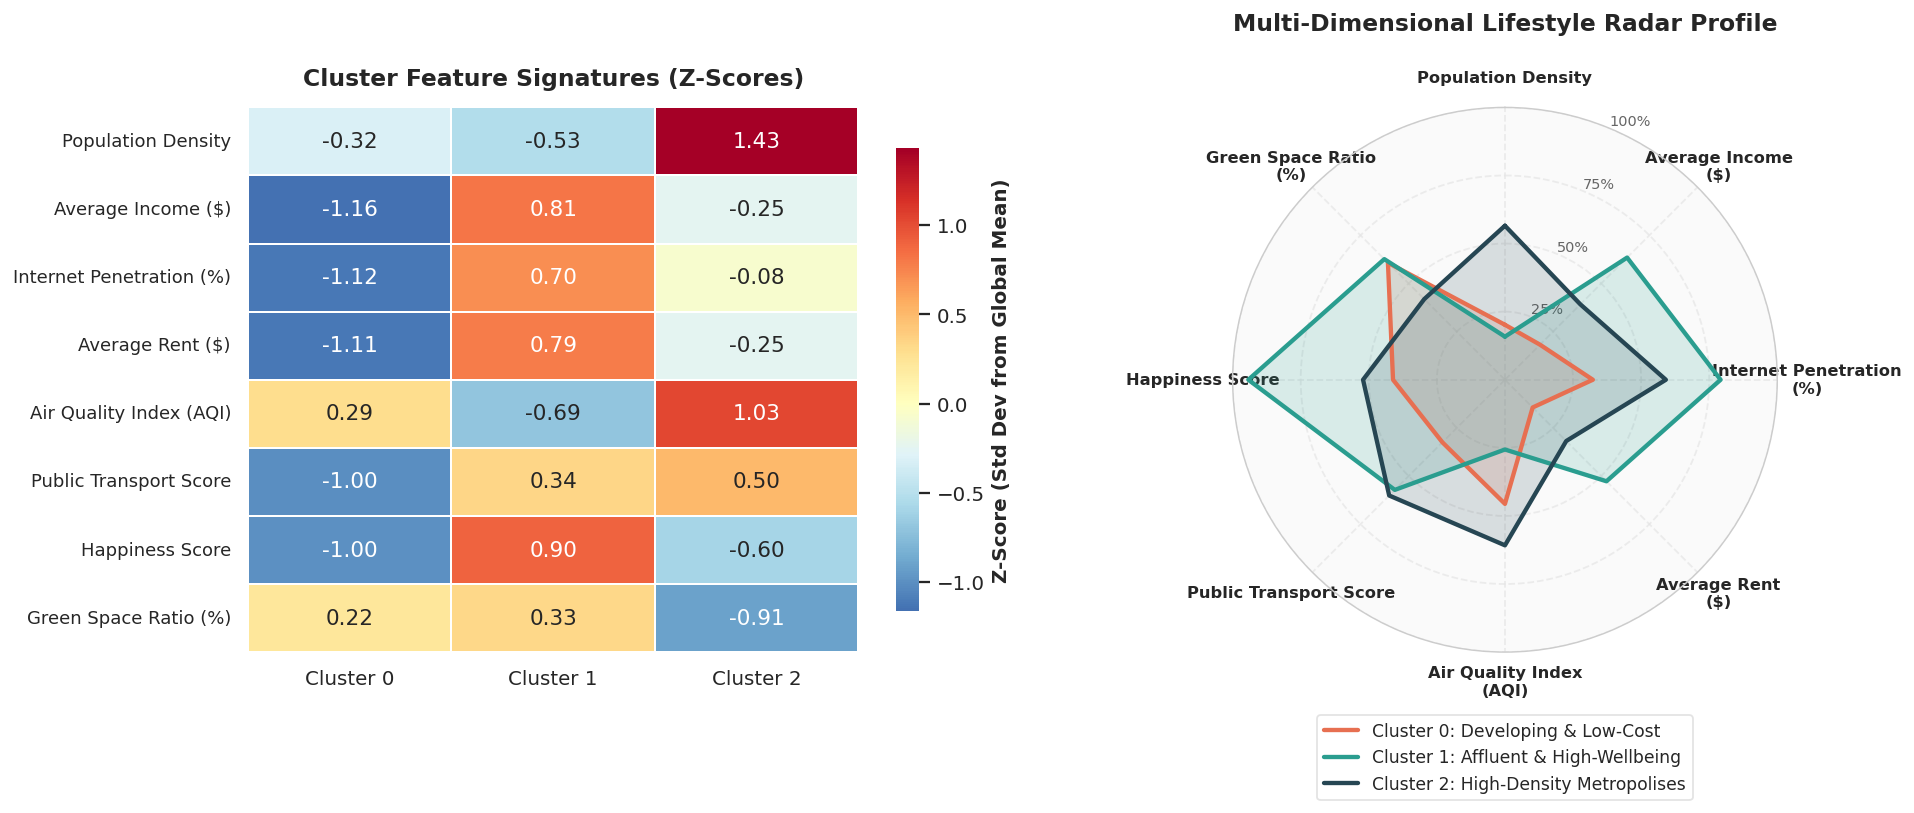

In [ ]:
# Mean profile table (unscaled)
cluster_means = df.groupby('cluster')[features].mean().round(2)
cluster_means.index = [CLUSTER_LABELS[i] for i in cluster_means.index]
print("=== Unscaled Cluster Mean Profiles ===")
print(cluster_means.to_string())

# Standardized Centroids (Z-scores)
centroids_z = pd.DataFrame(kmeans.cluster_centers_, columns=[pretty_names[f] for f in features])
centroids_z.index = [f'Cluster {i}' for i in range(optimal_k)]

# Create Combined Heatmap + Radar Chart Figure
fig = plt.figure(figsize=(15.5, 6.5))

# Left Subplot: Z-Score Heatmap
ax1 = fig.add_subplot(1, 2, 1)
sns.heatmap(
    centroids_z.T,
    annot=True,
    fmt='.2f',
    cmap='RdYlBu_r',
    center=0,
    linewidths=1.0,
    linecolor='white',
    cbar_kws={'label': 'Z-Score (Std Dev from Global Mean)', 'shrink': 0.85},
    ax=ax1
)
ax1.set_title('Cluster Feature Signatures (Z-Scores)', fontsize=13, fontweight='bold', pad=12)
ax1.set_xlabel('')
ax1.set_ylabel('')
ax1.tick_params(axis='y', labelsize=10)

# Right Subplot: Normalized Radar Chart (0 to 1 Min-Max across Cluster Means)
ax2 = fig.add_subplot(1, 2, 2, polar=True)
raw_means = df.groupby('cluster')[features].mean()
# Normalize against global min/max so radar values stay cleanly in [0, 1]
norm_means = (raw_means - df[features].min()) / (df[features].max() - df[features].min())

labels_radar = [pretty_names[f].replace(' (', '\n(') for f in features]
num_vars = len(features)
angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()
angles += angles[:1]

ax2.set_theta_offset(np.pi / 2)
ax2.set_theta_direction(-1)
ax2.set_xticks(angles[:-1])
ax2.set_xticklabels(labels_radar, fontsize=9, fontweight='bold')
ax2.set_ylim(0, 1.0)
ax2.set_yticks([0.25, 0.5, 0.75, 1.0])
ax2.set_yticklabels(['25%', '50%', '75%', '100%'], fontsize=8, color='#666666')
ax2.set_facecolor('#FAFAFA')

for c in sorted(df['cluster'].unique()):
    values = norm_means.loc[c].tolist()
    values += values[:1]
    ax2.plot(angles, values, linewidth=2.4, color=CLUSTER_PALETTE[c], label=CLUSTER_LABELS[c])
    ax2.fill(angles, values, color=CLUSTER_PALETTE[c], alpha=0.16)

ax2.set_title('Multi-Dimensional Lifestyle Radar Profile', fontsize=13, fontweight='bold', pad=22)
ax2.legend(loc='upper center', bbox_to_anchor=(0.5, -0.10), ncol=1, fontsize=9.5)

plt.tight_layout()
plt.show()

## 6. Feature-by-Feature Comparison & Regional Breakdown
Visualize the exact spread of key lifestyle indicators per cluster (boxplots) alongside the geographic distribution of cities across regions.

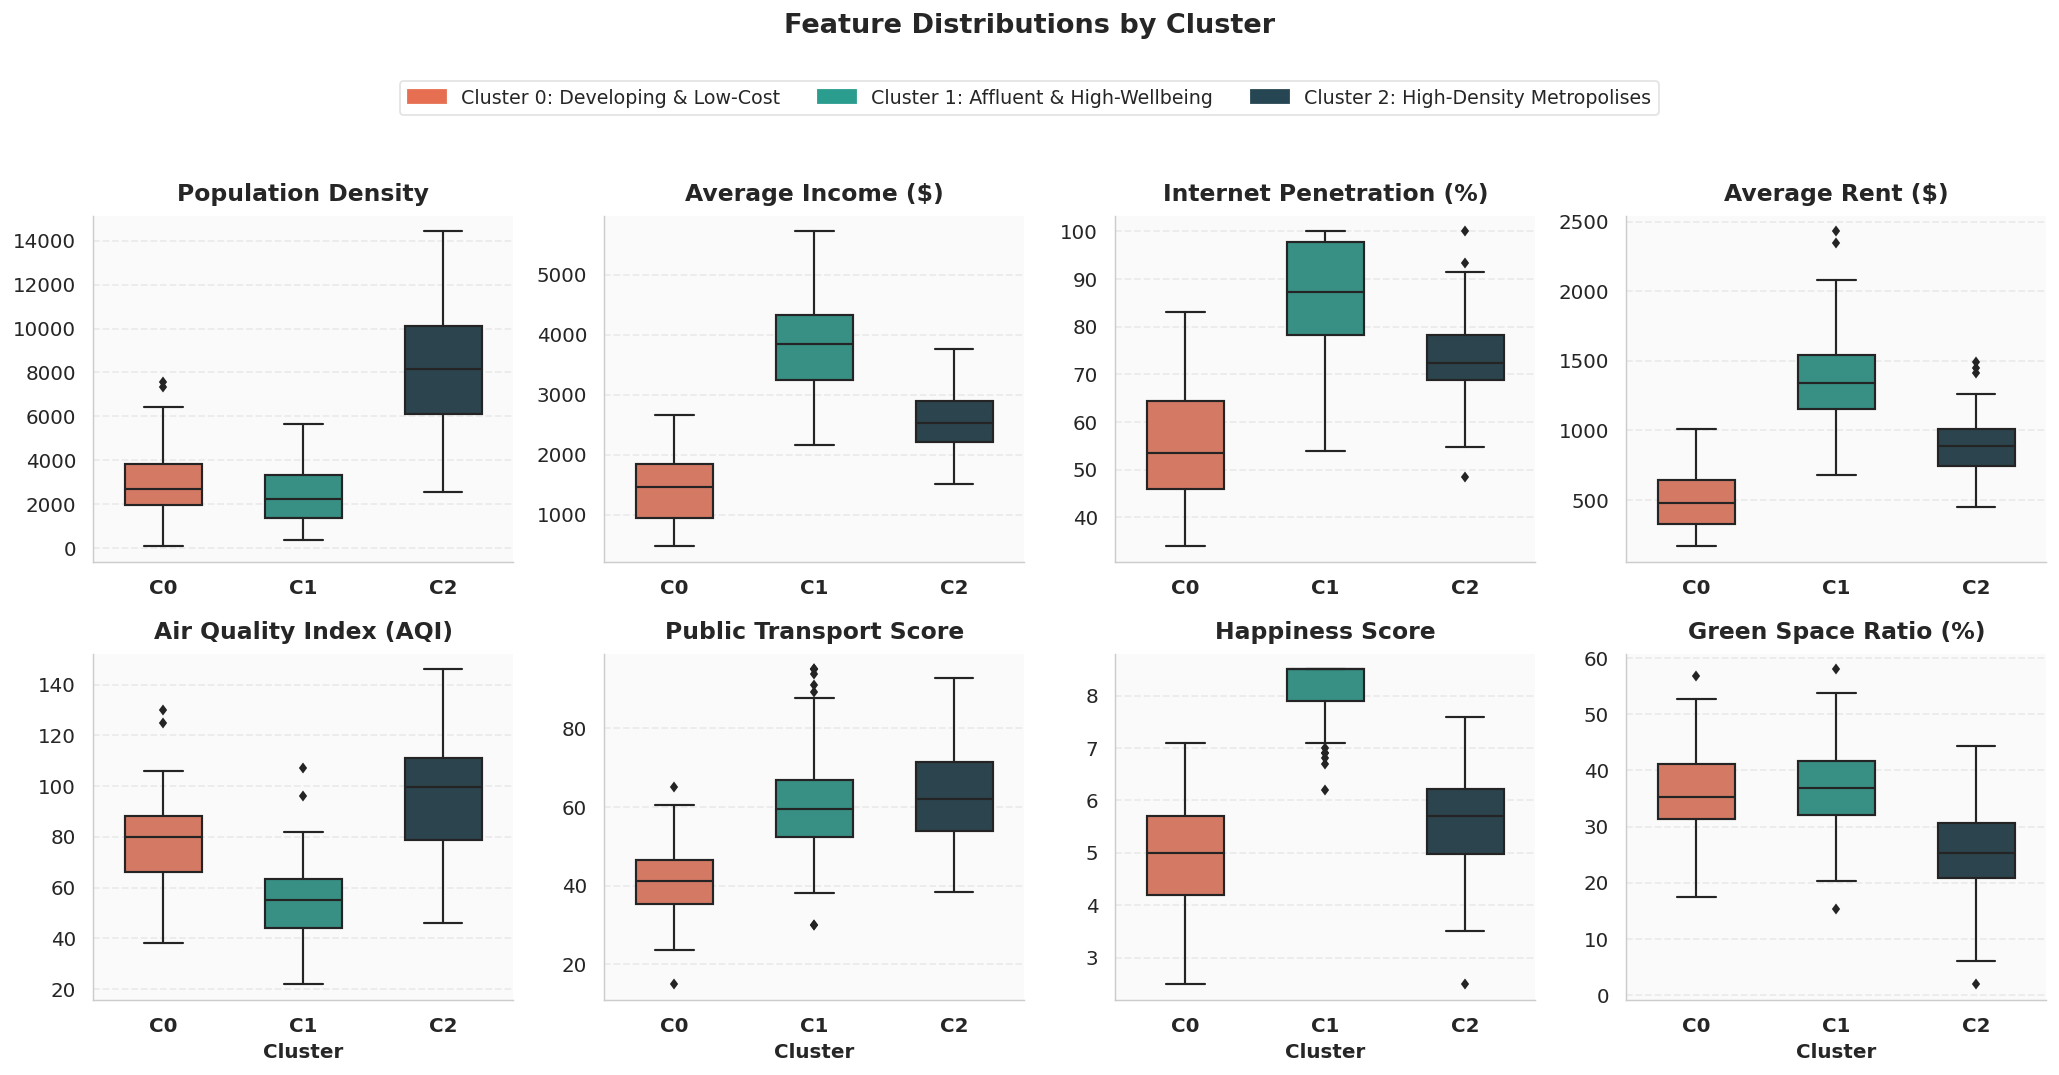

In [ ]:
# 2x4 Boxplot Grid across all 8 features
fig, axes = plt.subplots(2, 4, figsize=(16, 7.5))
axes = axes.flatten()
palette_list = [CLUSTER_PALETTE[0], CLUSTER_PALETTE[1], CLUSTER_PALETTE[2]]

for idx, col in enumerate(features):
    ax = axes[idx]
    sns.boxplot(
        data=df, x='cluster', y=col, palette=palette_list,
        width=0.55, fliersize=3.5, linewidth=1.2, ax=ax
    )
    ax.set_title(pretty_names[col], pad=8)
    ax.set_xlabel('Cluster' if idx >= 4 else '')
    ax.set_ylabel('')
    ax.set_xticklabels(['C0', 'C1', 'C2'], fontweight='bold')
    sns.despine(ax=ax)

legend_handles = [mpatches.Patch(color=CLUSTER_PALETTE[i], label=CLUSTER_LABELS[i]) for i in range(3)]
fig.legend(handles=legend_handles, loc='upper center', bbox_to_anchor=(0.5, 1.04), ncol=3, fontsize=10.5, frameon=True)
fig.suptitle('Feature Distributions by Cluster', fontsize=15, fontweight='bold', y=1.10)
plt.tight_layout()
plt.show()

=== Regional City Counts per Cluster ===
               Cluster 0  Cluster 1  Cluster 2  Total
country                                              
Africa                35          0          0     35
Asia                  13          5         62     80
Europe                 3         55          2     60
North America          2         47          1     50
Oceania                0         35          0     35
South America         32          1          7     40


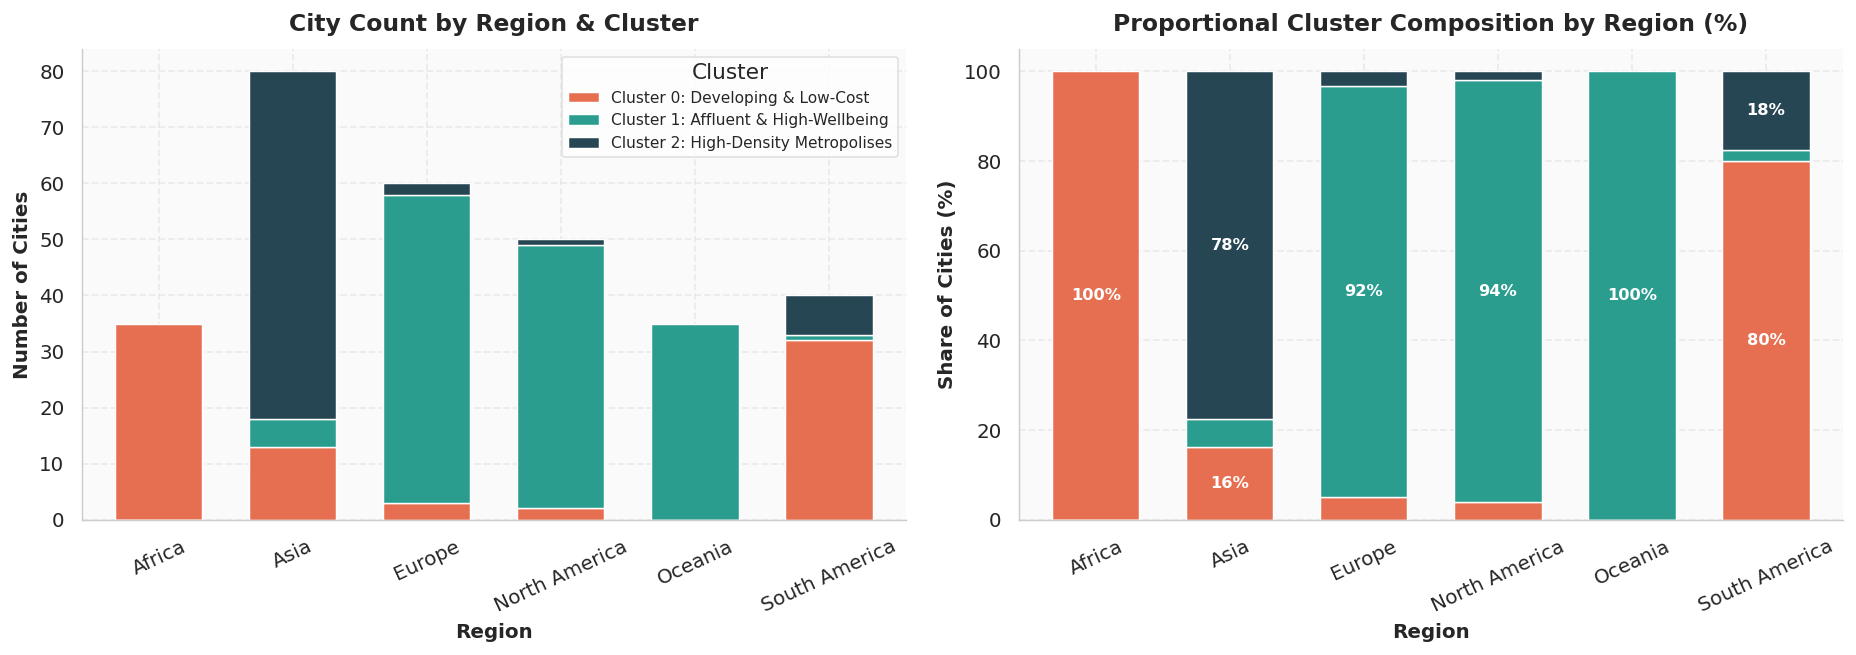

In [ ]:
# Regional Breakdown Stacked Bar Chart
region_ct = pd.crosstab(df['country'], df['cluster'])
region_ct_pct = region_ct.div(region_ct.sum(axis=1), axis=0) * 100

print("=== Regional City Counts per Cluster ===")
region_display = region_ct.copy()
region_display.columns = [f'Cluster {c}' for c in region_display.columns]
region_display['Total'] = region_display.sum(axis=1)
print(region_display.to_string())

fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.2))

# Left: Absolute counts
region_ct.plot(
    kind='bar', stacked=True, ax=axes[0],
    color=[CLUSTER_PALETTE[0], CLUSTER_PALETTE[1], CLUSTER_PALETTE[2]],
    edgecolor='white', linewidth=0.8, width=0.65
)
axes[0].set_title('City Count by Region & Cluster', pad=10)
axes[0].set_xlabel('Region')
axes[0].set_ylabel('Number of Cities')
axes[0].tick_params(axis='x', rotation=25)
axes[0].legend([CLUSTER_LABELS[i] for i in range(3)], title='Cluster', fontsize=8.5, loc='upper right')
sns.despine(ax=axes[0])

# Right: 100% Proportional Stacked Bar
region_ct_pct.plot(
    kind='bar', stacked=True, ax=axes[1],
    color=[CLUSTER_PALETTE[0], CLUSTER_PALETTE[1], CLUSTER_PALETTE[2]],
    edgecolor='white', linewidth=0.8, width=0.65, legend=False
)
for container in axes[1].containers:
    labels = [f'{v:.0f}%' if v >= 10 else '' for v in container.datavalues]
    axes[1].bar_label(container, labels=labels, label_type='center', color='white', fontweight='bold', fontsize=9)

axes[1].set_title('Proportional Cluster Composition by Region (%)', pad=10)
axes[1].set_xlabel('Region')
axes[1].set_ylabel('Share of Cities (%)')
axes[1].set_ylim(0, 105)
axes[1].tick_params(axis='x', rotation=25)
sns.despine(ax=axes[1])

plt.tight_layout()
plt.show()

## 7. Representative Cities & Export Final Clustered Dataset
Display top representative cities per cluster and save the final labeled dataset (`city_lifestyle_clustered.csv`).

In [ ]:
# Print representative sample cities for each cluster
for c in sorted(df['cluster'].unique()):
    print(f"\n--- {CLUSTER_LABELS[c]} (n = {(df['cluster'] == c).sum()}) ---")
    sample = df[df['cluster'] == c][['city_name', 'country', 'avg_income', 'avg_rent', 'population_density', 'air_quality_index', 'happiness_score']].head(5)
    print(sample.to_string(index=False))

# Export final clustered dataset
output_csv = '/content/city_lifestyle_clustered.csv' if os.path.exists('/content') else 'city_lifestyle_clustered.csv'
df.to_csv(output_csv, index=False)
print(f"\nSaved clustered dataset to: {output_csv}")


--- Cluster 0: Developing & Low-Cost (n = 85) ---
    city_name country  avg_income  avg_rent  population_density  air_quality_index  happiness_score
       Bridge  Europe        2660       980                3577                 79              5.8
  Harborshire  Europe        1850       760                2714                 56              6.1
   Harborport  Europe        2630       790                3319                 75              6.3
Gardenborough    Asia        2260      1010                5488                 81              5.4
     Old Wood    Asia         640       220                6448                 57              4.6

--- Cluster 1: Affluent & High-Wellbeing (n = 143) ---
    city_name country  avg_income  avg_rent  population_density  air_quality_index  happiness_score
    Old Vista  Europe        3850      1310                2775                 43              8.5
    Beachport  Europe        3700      1330                3861                 42           

---
## 8. Key Takeaways & Cluster Summary

| Cluster | Archetype | Cities | Defining Characteristics | Primary Regions |
| :--- | :--- | :---: | :--- | :--- |
| **Cluster 0** | **Developing & Low-Cost** | 85 (28.3%) | Lowest average income ($1,434), lowest rent ($495), lowest internet penetration (55.3%), weakest public transit (41.0), lowest happiness (4.97) | Africa (35), South America (32), Asia (13) |
| **Cluster 1** | **Affluent & High-Wellbeing** | 143 (47.7%) | Highest income ($3,804), highest rent ($1,362), strongest internet (86.3%), cleanest air (AQI 53.8), highest green space (37.1%), highest happiness (8.15) | Europe (55), North America (47), Oceania (35) |
| **Cluster 2** | **High-Density Metropolises** | 72 (24.0%) | Extreme population density (8,204 — ~3.5x Cluster 1), strongest public transit (63.1), poorest air quality (AQI 97.4), lowest green space (25.5%), mid-tier income ($2,532) | Asia (62), South America (7) |
